In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *
from anemone.forwards import*

In [2]:
from dataclasses import dataclass
@dataclass
class Sweep:
    data: np.ndarray
    time: np.ndarray
    error: np.ndarray
    quality: np.ndarray
    tx_ramp: np.ndarray
    tx_ramp_time: np.ndarray
    current: float
    frequency: float
    is_noise: bool
    field_shift_factor: float
    time_delay: float
    ramp_time: float
#    rx_frontgate: float
    tx_turnontime: float
    ramp_time_on: float
    number: int
    channel: int
    low_pass: np.ndarray
    points: int
    
    @classmethod
    def from_usf_text(cls, txt):
        """parse a sweep block, will return the next sweep"""
        sweep = {}
        lines = txt.lower().split('\n')
        i_head = lines.index('/end')
        for line in lines[:i_head]:
            i_colon = line.index(':')
            tmp = line[i_colon+1:]
            key = line[1:i_colon].replace('sweep_', '')
            if ',' in tmp:
                sweep[key] = np.array([float(x) for x in tmp.split(',')])
            else:
                sweep[key] = float(tmp)
        x = np.genfromtxt(lines[i_head+3:i_head+3+int(sweep['points'])], delimiter=',')#, dtype=(float,float,float,int))
        sweep['time'] = x[:, 0]
        sweep['data'] = x[:, 1]
        sweep['error']= x[:, 2]
        sweep['quality'] = x[:,3].astype(bool)
        tx_time = sweep['tx_ramp'][::2]*1
        tx_ramp = sweep['tx_ramp'][1::2]*1
        sweep['tx_ramp'] = tx_ramp
        sweep['tx_ramp_time'] = tx_time
        if 'rx_frontgate' in sweep: del sweep['rx_frontgate']
        return cls(**sweep)
    
    @staticmethod
    def combine_sweeps(sweep_list):
        mega_sweep = {}
        for key in vars(sweep_list[0]):
            x = np.array([eval(f'sweep.{key}') for sweep in sweep_list])
            mega_sweep[key] = x
        return Sweep(**mega_sweep)
    
    @classmethod
    def from_usf(cls, fname):
        """parse a usf file, will return """
        with open(fname, 'r') as f:
            txt = f.read()
            sweeps = []
            count = 0
            while '/SWEEP_NUMBER' in txt:
                i = txt.index('/SWEEP_NUMBER:')
                sweeps.append(Sweep.from_usf_text(txt[i:]))
                txt = txt[i+1:]

        points = set([x.points for x in sweeps])
        mega_sweeps = []
        for pnts in points:
            mega_sweeps.append(cls.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
        return mega_sweeps
    
    def flip_sign(self):
        self.data *= -1


    def get_polarity(self, gates=slice(4)):
        return np.sign(self.data[gates].mean())
    
    def correct_polarity(self, **kwargs):
        self.data *= self.get_polarity(**kwargs)        

    def save(self, fname):
        from pickle import dump
        with open(fname, 'wb') as outfile:
            dump(self, outfile)

    def estimate_noise(self, min_relative_error=0.03):
        dbdt_mean = self.data.mean(0)
        std=np.sqrt((min_relative_error*dbdt_mean)**2 + self.data.var(0))
        rstd = std/dbdt_mean
        dbdt_lb = (1-rstd)*dbdt_mean
        dbdt_ub = dbdt_mean**2 / dbdt_lb
        return dbdt_lb, dbdt_ub


    @classmethod
    def load(cls, fname, **kwargs):
        from pickle import load
        with open(fname, "rb") as a_file:
            data = load(a_file)
        return data

In [3]:
hm,lm = Sweep.from_usf("Z:/2024_sTEM_Fucheng/Data/sTEM Profiler/2024_1021/USF_Files_sTEMtest/L001_S038_2024_1021_055805.usf")

In [4]:
tx = Loop.square(3)
rx = Receiver(x=13)

recfilter  = FilterChain([
    ButterworthFilter(180000, 2),
    ButterworthFilter(800000, 1)
])

times = [torch.from_numpy(hm.time[0]), torch.from_numpy(lm.time[0])]
waveforms = [Waveform(hm.tx_ramp_time[0], hm.tx_ramp[0]), Waveform(lm.tx_ramp_time[0], lm.tx_ramp[0])]

In [5]:
fwr = DualMoment3(tx, rx, times,recfilter, waveforms)

c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)
c:\users\au653994\onedrive - aarhus universitet\documents\phd\anemone\src\anemone\forwards\forwards.py:137: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=self.device)


In [6]:
rho = torch.tensor([20, 80, 50])
thk = torch.tensor([20, 30])

dbdt_clean = fwr(rho, thk)

In [7]:
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)
    
dbdt_relerr = compute_relstd(tcat, dbdt_clean, moment=3)
dbdt_relerr[hm_slice] = compute_relstd(tcat, dbdt_clean, moment=30)[hm_slice]

In [8]:
noise = torch.abs(dbdt_clean*dbdt_relerr)

In [9]:
dbdt_obs = dbdt_clean + noise * torch.randn_like(dbdt_clean)

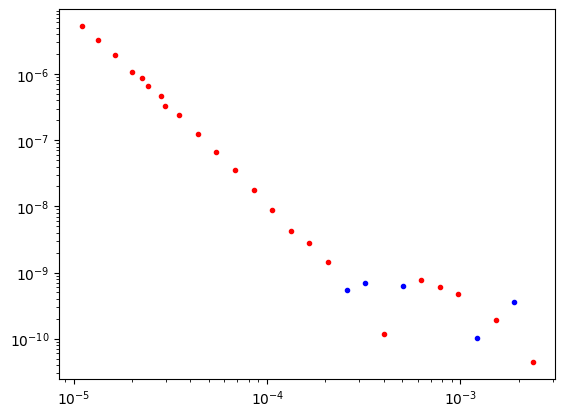

In [10]:
plt.figure()
plt.loglog(torch.concatenate(fwr.times), dbdt_obs, 'r.')
plt.loglog(torch.concatenate(fwr.times), -dbdt_obs, 'b.')

In [11]:
model = SmoothModel.starting_model(30, depth_bottom=150, rho=40.)
inv = Inversion(torch.abs(dbdt_obs), noise, model, fwr, data_transform=torch.log10)
res_mod = inv.invert(smoothness=1e1, iter_cap=10)

001	misfit:	4.02
002	misfit:	2.15
003	misfit:	1.69
004	misfit:	1.40
005	misfit:	1.29
006	misfit:	1.17
007	misfit:	1.44
008	misfit:	1.42
009	misfit:	1.14
010	misfit:	1.36
reached iteration cap..
reached iteration cap..

 10


In [13]:
mtrue = FewLayerModel(rho, thk)

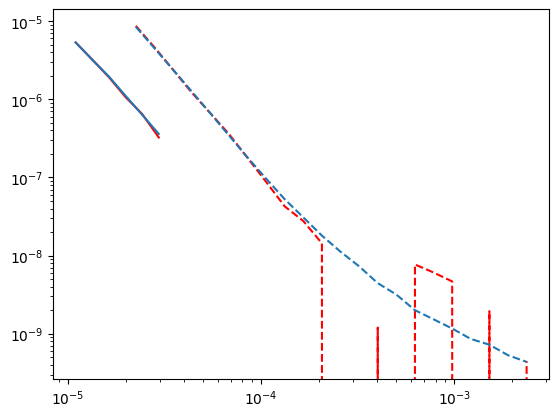

In [14]:
plt.figure()
plt.loglog(tcat[lm_slice],  dbdt_obs[lm_slice], 'r-')
plt.loglog(tcat[hm_slice],  10*dbdt_obs[hm_slice], 'r--')
dpred = fwr(*res_mod.mod)
plt.loglog(tcat[lm_slice],  dpred[lm_slice], 'C0-')
plt.loglog(tcat[hm_slice],  10*dpred[hm_slice], 'C0--')


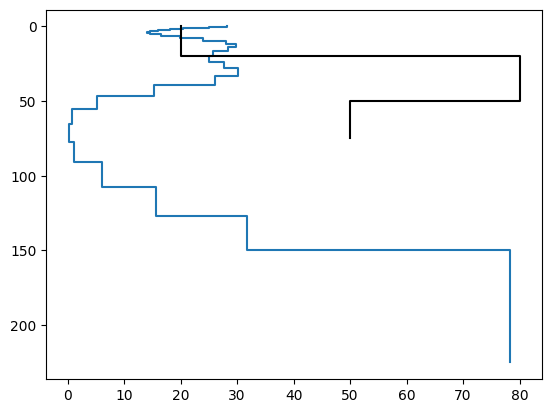

In [15]:
ax = res_mod.plot()
mtrue.plot(ax=ax, color='k')
ax.invert_yaxis()